# HW3. Автоэнкодер для восстановления рентгеновских снимков

Команда: Крутько, Кузнецова, Сумарокова, Драчук.
Группа: 640-01.

В этой работе мы адаптируем [пример из практики 3](https://github.com/VakhromeevaKate/nn-practice-2026/blob/main/practice3/autoencoder-model.ipynb) под датасет **PneumoniaMNIST**.

Автоэнкодер сначала сжимает изображение в короткий вектор, а затем восстанавливает его. Сравниваем варианты с 2, 8 и 32 числами в этом векторе. Входом и целевым ответом будет один и тот же снимок; метки классов понадобятся только для анализа.


## 1. Цель и границы проекта — Project Charter

| Поле | Описание |
|---|---|
| Название | Сжатие и восстановление рентгеновских изображений с помощью Vanilla AE |
| Заказчик и исполнитель | Учебный курс по нейронным сетям; Крутько, Кузнецова, Сумарокова, Драчук ||
| Проблема | При сильном сжатии изображения часть информации теряется. Нужно проверить, как размер скрытого представления влияет на восстановление снимка. |
| Цель | За один запуск ноутбука обучить три AE с `latent_dim = 2, 8, 32` по 15 эпох, сравнить MSE и время обучения. Ориентир для `dim=32` — MSE на validation ниже 0.02. |
| Входит в работу | Готовые разбиения данных, полносвязный AE, три эксперимента, таблицы, реконструкции и визуализация латентного пространства |
| Ограничения | Изображения 28 × 28, один seed, одинаковые настройки обучения; ограниченный бюджет вычислений Colab |
| Результат | Воспроизводимый ноутбук, веса моделей, метрики, графики и выводы |

Порог 0.02 взят как учебный ориентир из примера. Он не гарантирован заранее и сам по себе не означает, что сохранились все важные детали изображения.


## 2. План работы (WBS, Roadmap и Kanban)

| Этап | Задачи | Результат |
|---|---|---|
| 1. Подготовка | Описать цель, загрузить данные, проверить размеры и классы | Данные и примеры снимков |
| 2. Модель | Реализовать encoder, decoder и цикл обучения | Работающий AE |
| 3. Эксперименты | Обучить варианты 2, 8, 32; выбрать лучшие веса по validation | Истории обучения и таблица |
| 4. Анализ | Проверить модели на test, показать реконструкции и скрытые признаки | Метрики и графики |
| 5. Завершение | Сформулировать выводы, сохранить результаты | Отчёт и архив |

Этапы выполняются последовательно в одной сессии Colab. Длительность обучения каждого варианта будет измеряться в коде.

**Kanban на начало работы:**
- **Done:** выбраны задача, датасет и конфигурации экспериментов.
- **To do:** загрузка → обучение → визуализации → выводы.
- **Backlog:** сверточный AE, сравнение с PCA как моделью сжатия, несколько seed.

В конце ноутбука программно проверяются основные критерии готовности.


## 3. Риски и критерии готовности

| Риск | Вероятность / влияние | Что делаю |
|---|---|---|
| Модель переобучится | Средняя / высокое | Проверяю validation после каждой эпохи и сохраняю лучшие веса |
| Двух чисел окажется мало | Высокая / среднее | Сравниваю с 8 и 32, показываю одни и те же снимки |
| Обучение будет медленным | Низкая / среднее | Использую 28 × 28, компактную сеть и фиксированные 15 эпох |
| Классы не разделятся на графике | Средняя / среднее | Учитываю, что AE оптимизирует восстановление, а разделение классов не является его целью |
| Небольшая MSE скроет потерю деталей | Средняя / высокое | Дополняю число визуальным сравнением реконструкций |

**Definition of Done:** выполнены три запуска, сохранены лучшие веса, получены train/validation/test MSE, таблица экспериментов, графики обучения, реконструкции, scatter для dim=2, PCA и t-SNE для dim=32, выводы. Достижение MSE < 0.02 проверяется отдельно от технической готовности работы.


## 4. Данные и подготовка среды

**PneumoniaMNIST** содержит 5 856 рентгеновских снимков грудной клетки детей: `0` — норма, `1` — пневмония. Изображения уже приведены к одному каналу и размеру 28 × 28. Готовое разбиение: **4 708 train, 524 validation, 624 test**. [Описание в MedMNIST](https://github.com/MedMNIST/MedMNIST/blob/main/medmnist/info.py).

Данные доступны на [Zenodo](https://zenodo.org/records/10519652) под лицензией CC BY 4.0. Библиотека `medmnist` скачает нужный небольшой файл автоматически. Для работы беру подготовленную версию 28 × 28.

`ToTensor()` преобразует изображение в тензор `[1, 28, 28]` и переводит значения пикселей из `[0, 255]` в `[0, 1]`. Такой диапазон согласован с `Sigmoid` на выходе сети. Аугментации в этом эксперименте не использую.


In [1]:
%pip -q install medmnist==3.0.2


In [2]:
import json
import os
import platform
import random
import shutil
import time
from pathlib import Path

import medmnist
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import torch
import torch.nn as nn
import torchvision
from IPython.display import Markdown, display
from medmnist import PneumoniaMNIST
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from torch.utils.data import DataLoader
from torchvision import transforms

SEED = 42
BATCH_SIZE = 128
EPOCHS = 15
LEARNING_RATE = 1e-3
LATENT_DIMS = [2, 8, 32]

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

DATA_DIR = Path("data")
OUTPUT_DIR = Path("pneumonia_ae_results")
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"font.size": 11, "figure.dpi": 110})

versions = {
    "python": platform.python_version(), "torch": torch.__version__,
    "torchvision": torchvision.__version__, "medmnist": medmnist.__version__,
    "numpy": np.__version__, "pandas": pd.__version__,
    "matplotlib": matplotlib.__version__, "sklearn": sklearn.__version__,
}
print("Устройство:", device)
print(json.dumps(versions, ensure_ascii=False, indent=2))


Устройство: cuda
{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "torchvision": "0.29.1+cu130",
  "medmnist": "3.0.2",
  "numpy": "2.4.6",
  "pandas": "2.2.3",
  "matplotlib": "3.10.0",
  "sklearn": "1.6.1"
}


In [3]:
transform = transforms.ToTensor()
train_ds = PneumoniaMNIST(
    split="train", root=str(DATA_DIR), transform=transform, download=True
)
val_ds = PneumoniaMNIST(
    split="val", root=str(DATA_DIR), transform=transform, download=False
)
test_ds = PneumoniaMNIST(
    split="test", root=str(DATA_DIR), transform=transform, download=False
)
class_names = ["Норма", "Пневмония"]

# Метаданные и число примеров можно проверить до обучения.
# Изображения test используем для анализа только после выбора моделей.
rows = []
for split, dataset in [("train", train_ds), ("validation", val_ds), ("test", test_ds)]:
    labels = dataset.labels.reshape(-1)
    counts = np.bincount(labels, minlength=2)
    rows.append({
        "split": split, "Всего": len(dataset),
        "Норма": int(counts[0]), "Пневмония": int(counts[1]),
    })
    assert dataset.imgs.shape == (len(dataset), 28, 28)
    assert set(np.unique(labels)) == {0, 1}

split_df = pd.DataFrame(rows).set_index("split")
display(split_df)
sample, _ = train_ds[0]
assert sample.shape == (1, 28, 28)
assert torch.isfinite(sample).all() and 0 <= sample.min() <= sample.max() <= 1
print("Один снимок:", tuple(sample.shape), "| тип:", sample.dtype)


100%|██████████| 4.17M/4.17M [00:07<00:00, 548kB/s]


,Всего,Норма,Пневмония
split,,,
train,4708,1214,3494
validation,524,135,389
test,624,234,390


Один снимок: (1, 28, 28) | тип: torch.float32


### Примеры и баланс классов

Выведем несколько случайно выбранных обучающих снимков каждого класса и их количество. В train больше снимков с пневмонией, поэтому дополнительно посчитаем ошибку восстановления отдельно для каждого класса на test. Метки не передаются в модель и не участвуют в функции потерь.

Готовое разбиение сохраняем. В этом небольшом эксперименте отдельная ручная чистка не требуется: размеры и формат уже стандартизированы.


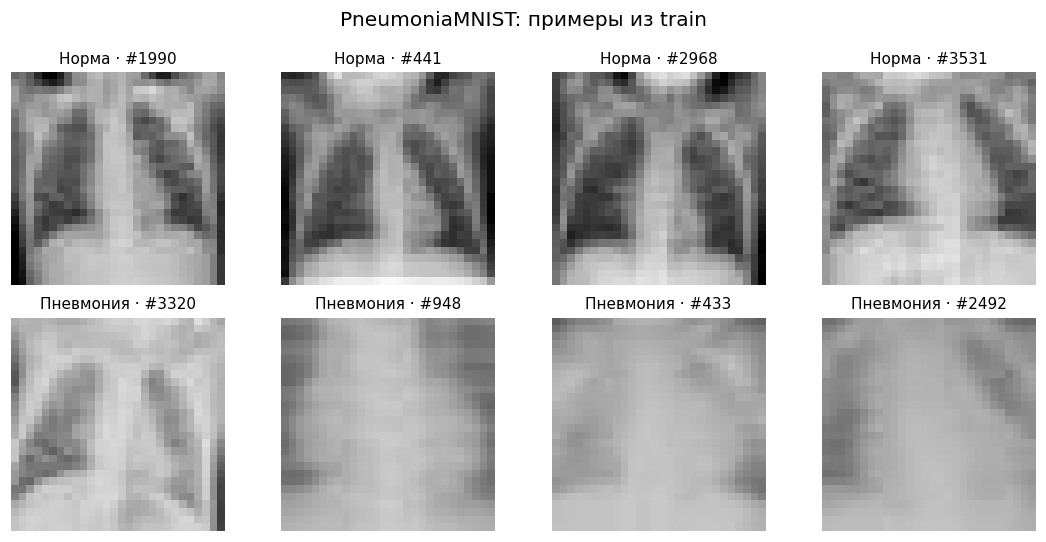

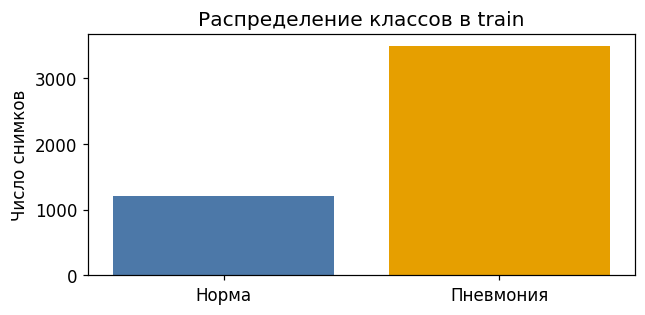

In [4]:
rng = np.random.default_rng(SEED)
train_labels = train_ds.labels.reshape(-1)
fig, axes = plt.subplots(2, 4, figsize=(10, 5))
for cls in range(2):
    indices = rng.choice(np.flatnonzero(train_labels == cls), size=4, replace=False)
    for col, idx in enumerate(indices):
        image, _ = train_ds[int(idx)]
        axes[cls, col].imshow(image.squeeze().numpy(), cmap="gray", vmin=0, vmax=1)
        axes[cls, col].set_title(f"{class_names[cls]} · #{idx}", fontsize=10)
        axes[cls, col].axis("off")
fig.suptitle("PneumoniaMNIST: примеры из train")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "train_examples.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(class_names, np.bincount(train_labels, minlength=2), color=["#4c78a8", "#e69f00"])
ax.set(title="Распределение классов в train", ylabel="Число снимков")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "class_distribution.png", bbox_inches="tight")
plt.show()


## 5. Архитектура автоэнкодера

Используем полносвязную сеть, как в примере:

`784 → 256 → 64 → latent_dim → 64 → 256 → 784`.

`Flatten` разворачивает снимок в 784 числа. **Encoder** сжимает его в вектор `z`, а **decoder** восстанавливает изображение. Между скрытыми слоями стоит `ReLU`; выходной `Sigmoid` ограничивает яркость диапазоном `[0, 1]`. Затем `Unflatten` возвращает форму `[1, 28, 28]`.

Меняется только размер `z`: 2, 8 или 32. Это размер представления в числах, а не измерение размера сжатого файла. Ошибка **MSE** — средний квадрат разности исходных и восстановленных пикселей; меньшее значение означает более точное совпадение.


In [5]:
class Autoencoder(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(28 * 28, 256), nn.ReLU(),
            nn.Linear(256, 64), nn.ReLU(),
            nn.Linear(64, latent_dim),
        )
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64), nn.ReLU(),
            nn.Linear(64, 256), nn.ReLU(),
            nn.Linear(256, 28 * 28), nn.Sigmoid(),
            nn.Unflatten(1, (1, 28, 28)),
        )

    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z), z

# Небольшая проверка перед обучением.
with torch.no_grad():
    demo = Autoencoder(latent_dim=32)
    reconstructed, z = demo(torch.zeros(4, 1, 28, 28))
assert reconstructed.shape == (4, 1, 28, 28) and z.shape == (4, 32)
print("Восстановление:", reconstructed.shape, "| латент:", z.shape)
del demo


Восстановление: torch.Size([4, 1, 28, 28]) | латент: torch.Size([4, 32])


## 6. Обучение и выбор весов

Каждый вариант обучается 15 эпох с `Adam`, `lr = 0.001` и batch size 128. Перед каждым запуском сбрасываем seed и отдельно фиксируем порядок обучающих батчей. Разные размеры слоёв всё равно означают разные начальные веса; один seed не заменяет несколько независимых повторов.

После каждой эпохи считаю MSE на validation без обновления весов. Сохраняем состояние с минимальной validation MSE и возвращаем именно его. Для итоговой таблицы заново оцениваем train и validation у выбранного состояния. Тест в обучении не используется.

На графике `train_mse` считается по батчам во время обновления весов, а `val_mse` — после эпохи. Время включает обучение и валидацию; на GPU перед измерением дожидаемся завершения вычислений.


In [6]:
criterion = nn.MSELoss()
train_eval_loader = DataLoader(train_ds, batch_size=256, shuffle=False, num_workers=0)
val_loader = DataLoader(val_ds, batch_size=256, shuffle=False, num_workers=0)
test_loader = DataLoader(test_ds, batch_size=256, shuffle=False, num_workers=0)

@torch.no_grad()
def evaluate_mse(model, loader):
    model.eval()
    total = 0.0
    for images, _ in loader:
        images = images.to(device)
        reconstructed, _ = model(images)
        # Взвешиваем по размеру батча: последний батч может быть меньше.
        total += criterion(reconstructed, images).item() * len(images)
    return total / len(loader.dataset)

def synchronize():
    if device.type == "cuda":
        torch.cuda.synchronize()

def train_autoencoder(latent_dim):
    set_seed()
    generator = torch.Generator().manual_seed(SEED)
    train_loader = DataLoader(
        train_ds, batch_size=BATCH_SIZE, shuffle=True,
        generator=generator, num_workers=0,
    )
    model = Autoencoder(latent_dim).to(device)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    best_val, best_epoch, best_state = float("inf"), 0, None
    history = []

    for epoch in range(1, EPOCHS + 1):
        synchronize()
        started = time.perf_counter()
        model.train()
        running_loss = 0.0
        for images, _ in train_loader:
            images = images.to(device)
            optimizer.zero_grad(set_to_none=True)
            reconstructed, _ = model(images)
            loss = criterion(reconstructed, images)
            loss.backward()
            optimizer.step()
            running_loss += loss.item() * len(images)

        train_mse = running_loss / len(train_ds)
        val_mse = evaluate_mse(model, val_loader)
        if val_mse < best_val:
            best_val, best_epoch = val_mse, epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        synchronize()
        seconds = time.perf_counter() - started
        history.append({
            "epoch": epoch, "train_mse": train_mse,
            "val_mse": val_mse, "seconds": seconds,
        })
        print(f"dim={latent_dim:2d} | {epoch:02d}/{EPOCHS} | "
              f"train={train_mse:.5f} | val={val_mse:.5f} | {seconds:.1f} с")

    model.load_state_dict(best_state)
    model.eval()
    record = {
        "run_id": f"ae_dim{latent_dim}_seed{SEED}",
        "latent_dim": latent_dim, "seed": SEED,
        "epochs": EPOCHS, "lr": LEARNING_RATE, "batch_size": BATCH_SIZE,
        "best_epoch": best_epoch,
        "train_mse": evaluate_mse(model, train_eval_loader),
        "val_mse": evaluate_mse(model, val_loader),
        "training_seconds": sum(row["seconds"] for row in history),
        "parameters": sum(p.numel() for p in model.parameters()),
    }
    torch.save({"state_dict": best_state, "config": record}, OUTPUT_DIR / f"ae_dim{latent_dim}.pt")
    return model, pd.DataFrame(history), record


In [7]:
models, histories, results = {}, {}, []
for latent_dim in LATENT_DIMS:
    print(f"\nОбучение: latent_dim = {latent_dim}")
    model, history, record = train_autoencoder(latent_dim)
    models[latent_dim] = model
    histories[latent_dim] = history
    results.append(record)

results_df = pd.DataFrame(results)
display(results_df.round(6))

# Размер представления выбираем по validation, до итоговой оценки на test.
best_ld = int(results_df.loc[results_df["val_mse"].idxmin(), "latent_dim"])
print("Наименьшая validation MSE у варианта с latent_dim =", best_ld)



Обучение: latent_dim = 2
dim= 2 | 01/15 | train=0.01987 | val=0.01557 | 0.9 с
dim= 2 | 02/15 | train=0.01371 | val=0.01153 | 0.6 с
dim= 2 | 03/15 | train=0.01082 | val=0.01014 | 0.6 с
dim= 2 | 04/15 | train=0.00975 | val=0.00923 | 0.6 с
dim= 2 | 05/15 | train=0.00906 | val=0.00889 | 0.7 с
dim= 2 | 06/15 | train=0.00886 | val=0.00875 | 0.6 с
dim= 2 | 07/15 | train=0.00876 | val=0.00868 | 0.5 с
dim= 2 | 08/15 | train=0.00870 | val=0.00859 | 0.5 с
dim= 2 | 09/15 | train=0.00868 | val=0.00862 | 0.5 с
dim= 2 | 10/15 | train=0.00866 | val=0.00858 | 0.5 с
dim= 2 | 11/15 | train=0.00861 | val=0.00850 | 0.5 с
dim= 2 | 12/15 | train=0.00857 | val=0.00848 | 0.5 с
dim= 2 | 13/15 | train=0.00858 | val=0.00848 | 0.5 с
dim= 2 | 14/15 | train=0.00856 | val=0.00849 | 0.5 с
dim= 2 | 15/15 | train=0.00857 | val=0.00845 | 0.5 с

Обучение: latent_dim = 8
dim= 8 | 01/15 | train=0.02010 | val=0.01624 | 0.5 с
dim= 8 | 02/15 | train=0.01537 | val=0.01431 | 0.5 с
dim= 8 | 03/15 | train=0.01208 | val=0.01086 | 

,run_id,latent_dim,seed,epochs,lr,batch_size,best_epoch,train_mse,val_mse,training_seconds,parameters
0,ae_dim2_seed42,2,42,15,0.001,128,15,0.008517,0.008453,8.577126,435858
1,ae_dim8_seed42,8,42,15,0.001,128,15,0.006629,0.006532,8.083090,436632
2,ae_dim32_seed42,32,42,15,0.001,128,15,0.006123,0.006061,7.500266,439728


Наименьшая validation MSE у варианта с latent_dim = 32


### Кривые обучения

Сравниыаем, как уменьшается ошибка и расходятся ли кривые train и validation. Вертикальная линия отмечает эпоху, веса которой сохранены. Итоговые метрики относятся к этим весам, а не обязательно к последней эпохе.


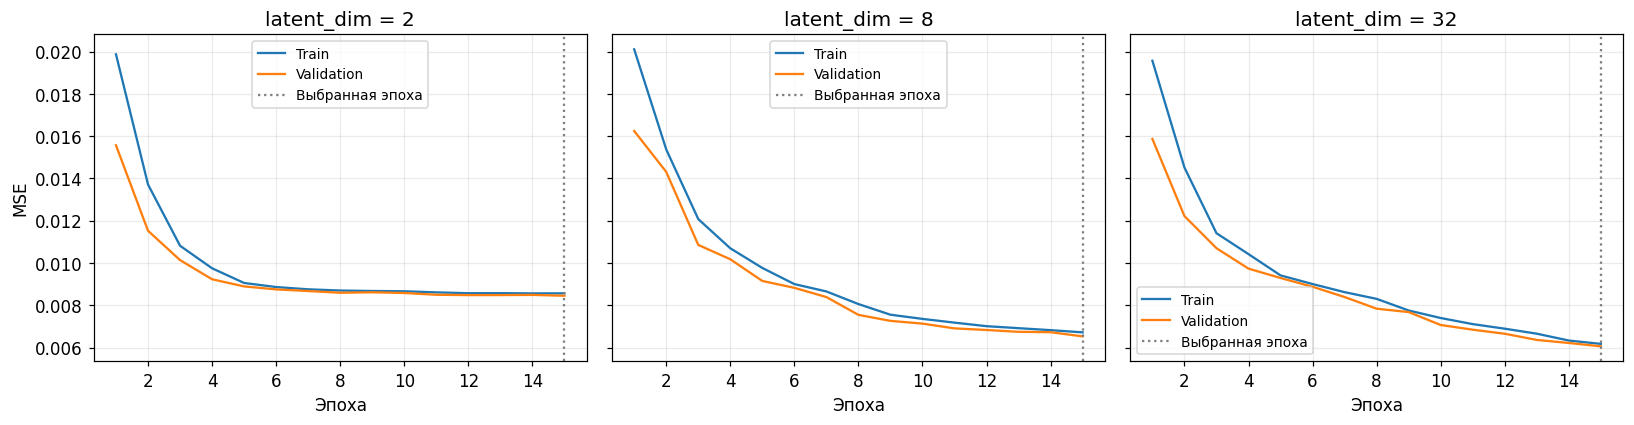

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, latent_dim in zip(axes, LATENT_DIMS):
    history = histories[latent_dim]
    best_epoch = int(results_df.loc[results_df["latent_dim"] == latent_dim, "best_epoch"].iloc[0])
    ax.plot(history["epoch"], history["train_mse"], label="Train")
    ax.plot(history["epoch"], history["val_mse"], label="Validation")
    ax.axvline(best_epoch, color="gray", linestyle=":", label="Выбранная эпоха")
    ax.set(title=f"latent_dim = {latent_dim}", xlabel="Эпоха")
    ax.grid(alpha=0.25)
    ax.legend(fontsize=9)
axes[0].set_ylabel("MSE")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "learning_curves.png", bbox_inches="tight")
plt.show()


## 7. Итоговая оценка на test

Конфигурации и веса уже выбраны. Теперь проверяем все три модели на одной и той же тестовой выборке. Кроме общей MSE, считаем её отдельно для нормы и пневмонии: классы представлены разным количеством снимков.

Эти значения описывают точность восстановления пикселей. Они не являются точностью распознавания пневмонии. По test не меняем настройки обучения и не выбираем основной вариант — он уже определён по validation.


In [9]:
@torch.no_grad()
def reconstruction_errors(model, loader):
    model.eval()
    errors, labels = [], []
    for images, targets in loader:
        images = images.to(device)
        reconstructed, _ = model(images)
        # Одна ошибка на снимок: среднее по каналу, высоте и ширине.
        batch_errors = (reconstructed - images).square().flatten(1).mean(1)
        errors.append(batch_errors.cpu().numpy())
        labels.append(targets.reshape(-1).numpy())
    return np.concatenate(errors), np.concatenate(labels)

test_records = []
test_errors = {}
for latent_dim in LATENT_DIMS:
    errors, labels = reconstruction_errors(models[latent_dim], test_loader)
    test_errors[latent_dim] = errors
    test_records.append({
        "latent_dim": latent_dim,
        "test_mse": float(errors.mean()),
        "test_normal_mse": float(errors[labels == 0].mean()),
        "test_pneumonia_mse": float(errors[labels == 1].mean()),
    })

comparison_df = results_df.merge(pd.DataFrame(test_records), on="latent_dim")
comparison_df["selected_on_validation"] = comparison_df["latent_dim"] == best_ld
columns = [
    "latent_dim", "best_epoch", "train_mse", "val_mse", "test_mse",
    "test_normal_mse", "test_pneumonia_mse", "training_seconds", "selected_on_validation",
]
display(comparison_df[columns].round(6))


,latent_dim,best_epoch,train_mse,val_mse,test_mse,test_normal_mse,test_pneumonia_mse,training_seconds,selected_on_validation
0,2,15,0.008517,0.008453,0.009142,0.013083,0.006777,8.577126,False
1,8,15,0.006629,0.006532,0.007073,0.010189,0.005204,8.083090,False
2,32,15,0.006123,0.006061,0.006584,0.009402,0.004893,7.500266,True


### Оригиналы и реконструкции

Покажем одинаковые восемь тестовых снимков для всех моделей: четыре случайных примера нормы и четыре — пневмонии. Индексы выбираются с фиксированным seed. Диапазон яркости `[0, 1]` одинаковый у всех изображений, чтобы сравнение было корректным.

На графике стоит обратить внимание на общую форму грудной клетки, контраст и размытие мелких деталей при сжатии.


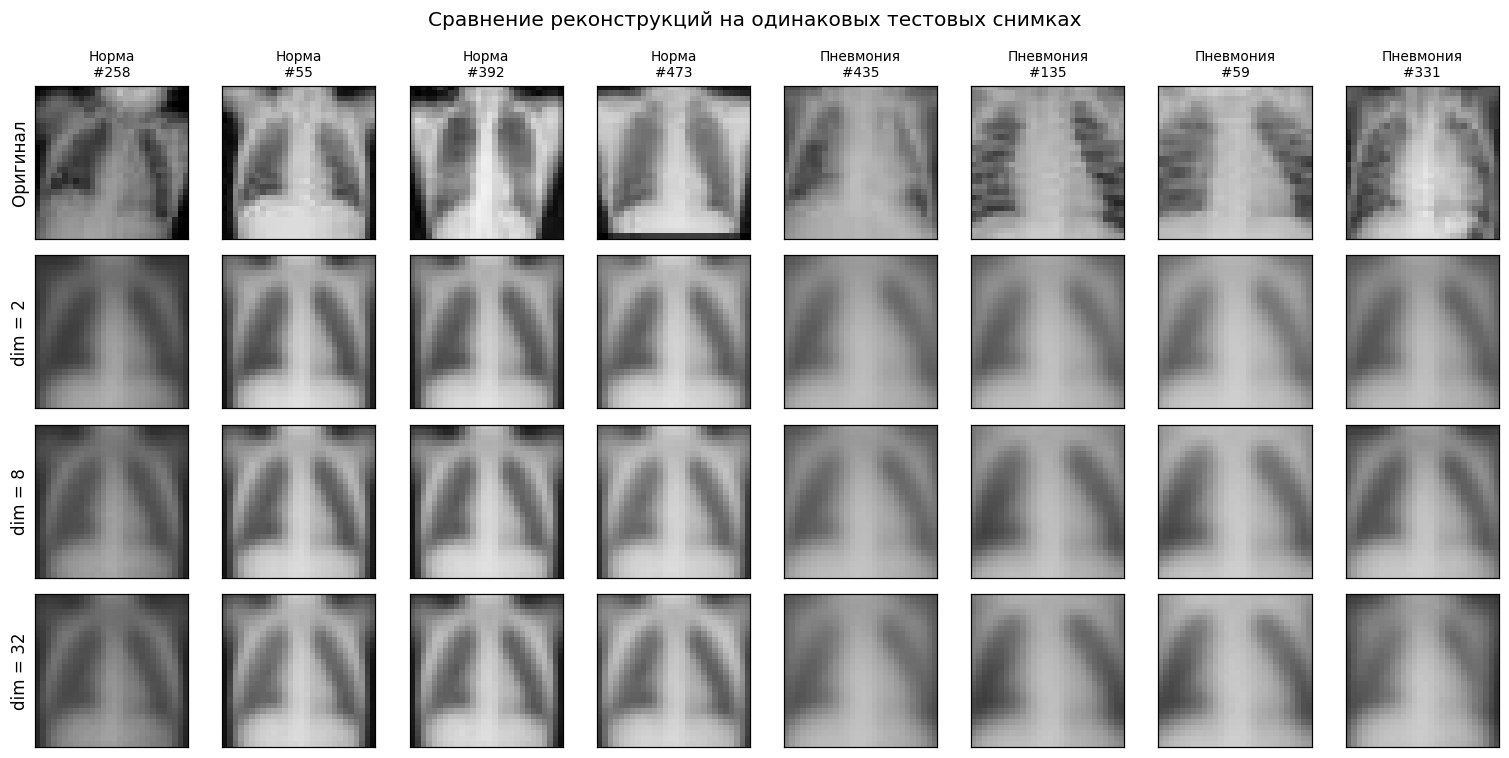

In [10]:
rng = np.random.default_rng(SEED)
test_labels = test_ds.labels.reshape(-1)
example_indices = np.concatenate([
    rng.choice(np.flatnonzero(test_labels == cls), size=4, replace=False)
    for cls in range(2)
])
example_images = torch.stack([test_ds[int(i)][0] for i in example_indices])
fig, axes = plt.subplots(4, 8, figsize=(14, 7))

for col, idx in enumerate(example_indices):
    axes[0, col].imshow(example_images[col, 0].numpy(), cmap="gray", vmin=0, vmax=1)
    axes[0, col].set_title(f"{class_names[test_labels[idx]]}\n#{idx}", fontsize=9)

with torch.no_grad():
    for row, latent_dim in enumerate(LATENT_DIMS, start=1):
        models[latent_dim].eval()
        reconstructions, _ = models[latent_dim](example_images.to(device))
        for col in range(8):
            axes[row, col].imshow(reconstructions[col, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1)

for row, name in enumerate(["Оригинал", "dim = 2", "dim = 8", "dim = 32"]):
    axes[row, 0].set_ylabel(name, fontsize=11)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
fig.suptitle("Сравнение реконструкций на одинаковых тестовых снимках")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "reconstructions.png", bbox_inches="tight")
plt.show()


## 8. Латентное пространство

Каждая точка — один тестовый снимок, её цвет соответствует исходному классу. Для `dim=2` можно непосредственно показать две координаты `z`. Для `dim=32` уменьшаю размерность до двух с помощью PCA и t-SNE. Все 624 тестовых снимка помещаются в эти визуализации, подвыборка не нужна.

Классы могут перекрываться: автоэнкодер учится восстанавливать снимки, а не разделять диагнозы. Картина t-SNE также зависит от настроек и seed; видимые группы сами по себе не подтверждают качество классификации.


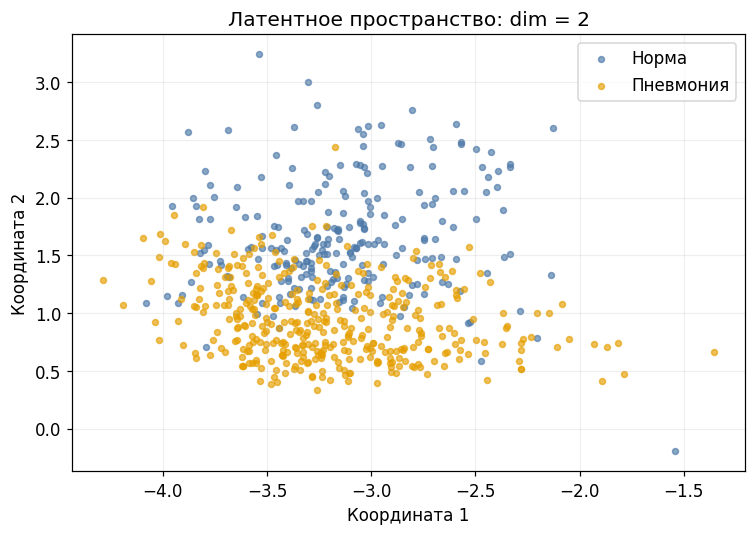

In [11]:
@torch.no_grad()
def get_latents(model, loader):
    model.eval()
    vectors, labels = [], []
    for images, targets in loader:
        z = model.encoder(images.to(device))
        vectors.append(z.cpu().numpy())
        labels.append(targets.reshape(-1).numpy())
    return np.concatenate(vectors), np.concatenate(labels)

def plot_latents(ax, coordinates, labels, title):
    for cls, color in [(0, "#4c78a8"), (1, "#e69f00")]:
        mask = labels == cls
        ax.scatter(coordinates[mask, 0], coordinates[mask, 1],
                   s=15, alpha=0.65, color=color, label=class_names[cls])
    ax.set(title=title, xlabel="Координата 1", ylabel="Координата 2")
    ax.grid(alpha=0.2)
    ax.legend()

Z2, Y2 = get_latents(models[2], test_loader)
fig, ax = plt.subplots(figsize=(7, 5))
plot_latents(ax, Z2, Y2, "Латентное пространство: dim = 2")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "latent_dim2.png", bbox_inches="tight")
plt.show()


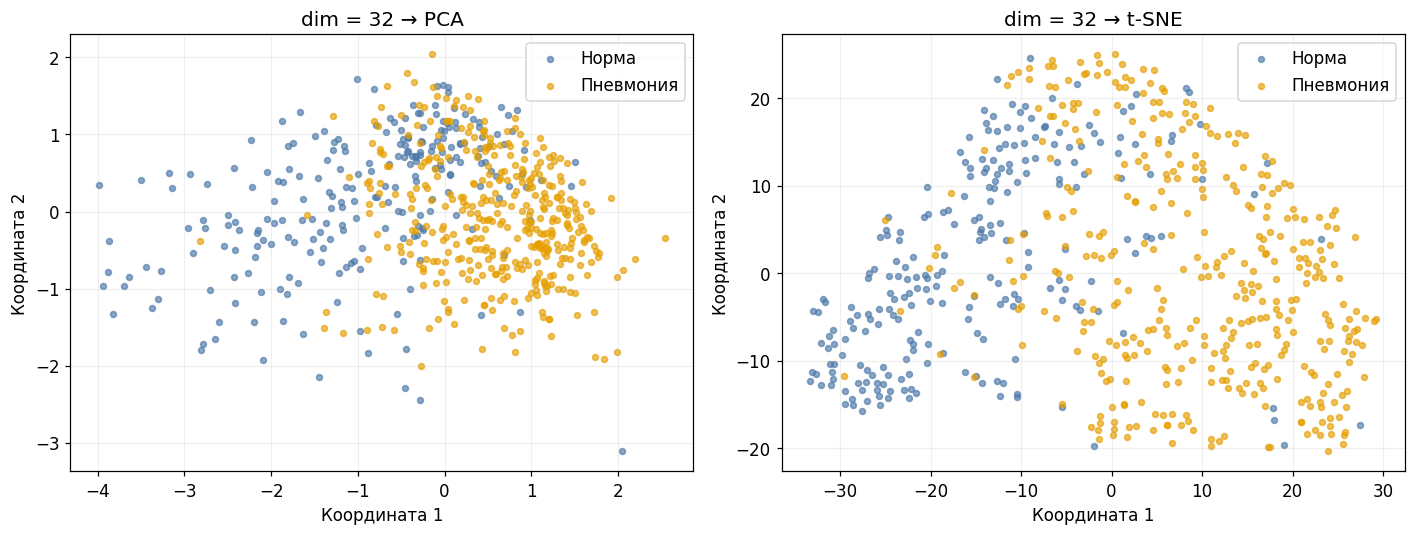

Первые две компоненты PCA объясняют 70.7% дисперсии.


In [12]:
Z32, Y32 = get_latents(models[32], test_loader)
pca = PCA(n_components=2, random_state=SEED)
Z_pca = pca.fit_transform(Z32)
Z_tsne = TSNE(
    n_components=2, perplexity=30, init="pca",
    learning_rate="auto", random_state=SEED,
).fit_transform(Z32)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
plot_latents(axes[0], Z_pca, Y32, "dim = 32 → PCA")
plot_latents(axes[1], Z_tsne, Y32, "dim = 32 → t-SNE")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "latent_dim32.png", bbox_inches="tight")
plt.show()
print(f"Первые две компоненты PCA объясняют {pca.explained_variance_ratio_.sum():.1%} дисперсии.")


## 9. Численные выводы и ретроспектива


In [14]:
metrics = comparison_df.set_index("latent_dim")
best_row = metrics.loc[best_ld]
change_percent = 100 * (metrics.loc[2, "test_mse"] - metrics.loc[32, "test_mse"]) / metrics.loc[2, "test_mse"]
direction = "ниже" if change_percent >= 0 else "выше"
target_reached = bool(metrics.loc[32, "val_mse"] < 0.02)
target_status = "достигнут" if target_reached else "не достигнут"

report = f"""### Результаты текущего запуска

Мы обучили три полносвязных автоэнкодера на одинаковых данных PneumoniaMNIST. Для каждого варианта использовали {EPOCHS} эпох, Adam, lr={LEARNING_RATE} и batch size {BATCH_SIZE}. Лучшие веса выбирались по validation.

- Минимальная validation MSE получена при **latent_dim={best_ld}**: **{best_row['val_mse']:.5f}**, выбранная эпоха — **{int(best_row['best_epoch'])}**. Test MSE этой модели равна **{best_row['test_mse']:.5f}**.
- Test MSE для dim=2: **{metrics.loc[2, 'test_mse']:.5f}**; для dim=8: **{metrics.loc[8, 'test_mse']:.5f}**; для dim=32: **{metrics.loc[32, 'test_mse']:.5f}**.
- У варианта dim=32 тестовая ошибка на **{abs(change_percent):.1f}% {direction}**, чем у dim=2, в этом запуске. Монотонное улучшение с ростом размерности заранее не гарантируется.
- Ориентир validation MSE < 0.02 для dim=32 **{target_status}**: получено **{metrics.loc[32, 'val_mse']:.5f}**.

### Ретроспектива

**Что сделано:** учебный пример перенесён на медицинские изображения; сохранены готовые train/validation/test; выполнены три эксперимента, записаны метрики, веса и визуализации.

**Ограничения:** в работе использованы маленькие изображения 28 × 28 и один seed. MSE измеряет разницу пикселей, поэтому важна и проверка реконструкций глазами. Показатели для нормы и пневмонии относятся к восстановлению, а не к распознаванию болезни.

**Следующие шаги:** сравнить со сверточным автоэнкодером и PCA как отдельным методом сжатия; повторить эксперимент с несколькими seed. Для проверки устойчивости к шуму нужен отдельный эксперимент с добавлением шума — в этой работе его нет.
"""
display(Markdown(report))
(OUTPUT_DIR / "conclusions.md").write_text(report, encoding="utf-8")


### Результаты текущего запуска

Мы обучили три полносвязных автоэнкодера на одинаковых данных PneumoniaMNIST. Для каждого варианта использовали 15 эпох, Adam, lr=0.001 и batch size 128. Лучшие веса выбирались по validation.

- Минимальная validation MSE получена при **latent_dim=32**: **0.00606**, выбранная эпоха — **15**. Test MSE этой модели равна **0.00658**.
- Test MSE для dim=2: **0.00914**; для dim=8: **0.00707**; для dim=32: **0.00658**.
- У варианта dim=32 тестовая ошибка на **28.0% ниже**, чем у dim=2, в этом запуске. Монотонное улучшение с ростом размерности заранее не гарантируется.
- Ориентир validation MSE < 0.02 для dim=32 **достигнут**: получено **0.00606**.

### Ретроспектива

**Что сделано:** учебный пример перенесён на медицинские изображения; сохранены готовые train/validation/test; выполнены три эксперимента, записаны метрики, веса и визуализации.

**Ограничения:** в работе использованы маленькие изображения 28 × 28 и один seed. MSE измеряет разницу пикселей, поэтому важна и проверка реконструкций глазами. Показатели для нормы и пневмонии относятся к восстановлению, а не к распознаванию болезни.

**Следующие шаги:** сравнить со сверточным автоэнкодером и PCA как отдельным методом сжатия; повторить эксперимент с несколькими seed. Для проверки устойчивости к шуму нужен отдельный эксперимент с добавлением шума — в этой работе его нет.


1375

### Наблюдения по графикам

- Ошибка всех моделей снижается; за 15 эпох явных признаков переобучения на графиках не наблюдается.
- Лучший результат среди проверенных вариантов получен при latent_dim=32. Тестовая MSE примерно на 28% ниже, чем при dim=2.
- Реконструкции сохраняют общие очертания снимков, но остаются размытыми. Мелкие детали восстанавливаются не полностью.
- В латентном пространстве видно частичное разделение классов, однако они перекрываются. Это не является оценкой точности классификации.
- Первые две компоненты PCA объясняют 70.7% дисперсии скрытых представлений.

## 10. Сохранение и проверка готовности

В папке `pneumonia_ae_results` сохраняются веса трёх моделей (`.pt`), полная таблица экспериментов, истории обучения, графики, конфигурация и численные выводы. Следующая ячейка соберёт папку в ZIP-архив.

In [15]:
comparison_df.to_csv(OUTPUT_DIR / "experiments.csv", index=False)
history_df = pd.concat(
    [history.assign(latent_dim=ld) for ld, history in histories.items()],
    ignore_index=True,
)
history_df.to_csv(OUTPUT_DIR / "learning_history.csv", index=False)
config = {
    "dataset": "PneumoniaMNIST", "image_size": 28,
    "seed": SEED, "latent_dims": LATENT_DIMS, "epochs": EPOCHS,
    "lr": LEARNING_RATE, "batch_size": BATCH_SIZE,
    "selected_latent_dim": best_ld, "selection_metric": "validation MSE",
    "device": str(device), "versions": versions,
    "reconstruction_example_indices": example_indices.tolist(),
}
(OUTPUT_DIR / "config.json").write_text(
    json.dumps(config, ensure_ascii=False, indent=2), encoding="utf-8"
)

required_figures = [
    "train_examples.png", "class_distribution.png", "learning_curves.png",
    "reconstructions.png", "latent_dim2.png", "latent_dim32.png",
]
checks = {
    "Выполнены три эксперимента": len(comparison_df) == 3,
    "Веса моделей сохранены": all((OUTPUT_DIR / f"ae_dim{ld}.pt").exists() for ld in LATENT_DIMS),
    "Ошибки конечные": bool(np.isfinite(comparison_df[["train_mse", "val_mse", "test_mse"]]).all().all()),
    "Train MSE снизилась за обучение": all(h["train_mse"].iloc[-1] < h["train_mse"].iloc[0] for h in histories.values()),
    "Графики сохранены": all((OUTPUT_DIR / name).exists() for name in required_figures),
    "Выводы сохранены": (OUTPUT_DIR / "conclusions.md").exists(),
}
display(pd.DataFrame({"Критерий": list(checks), "Выполнен": list(checks.values())}))
print("Целевой ориентир MSE < 0.02 для dim=32:", target_status)

archive_path = shutil.make_archive(str(OUTPUT_DIR), "zip", root_dir=OUTPUT_DIR)
print("Архив результатов:", archive_path)
print("Сохраните также сам выполненный ноутбук .ipynb.")


,Критерий,Выполнен
0,Выполнены три эксперимента,True
1,Веса моделей сохранены,True
2,Ошибки конечные,True
3,Train MSE снизилась за обучение,True
4,Графики сохранены,True
5,Выводы сохранены,True


Целевой ориентир MSE < 0.02 для dim=32: достигнут
Архив результатов: /content/pneumonia_ae_results.zip
Сохраните также сам выполненный ноутбук .ipynb.
